# Pronóstico mensual de tarifas spot de camión refrigerado por lane
### Entregable 4: Implementación, entrenamiento y evaluación del modelo

**Maestría en Inteligencia Artificial Aplicada**
Inteligencia Artificial y Aprendizaje Automático (TC4058.2)
**Equipo 1**

| Integrante | Matrícula |
|---|---|
| Jaime Martínez Vogel | A01283238 |
| Héctor de Luna Aguilar | A01610988 |

### Descripción del caso
Retomamos el caso del distribuidor de frutas y verduras frescas que mueve producto en camiones refrigerados y que necesita estimar cuánto le va a costar el flete spot el mes siguiente, tanto para armar su presupuesto como para decidir en qué momento le conviene amarrar un contrato con un transportista. En el Entregable 3 obtuvimos, limpiamos y preparamos los datos de USDA y de la EIA, y en este entregable construimos el prototipo predictivo, lo comparamos contra referencias simples y evaluamos si realmente aporta algo al negocio.

### Cambios a partir de la retroalimentación del Entregable 3
1. **Selección de lanes en cada corte.** En el E3 elegimos las 94 lanes con información hasta octubre de 2026 y después separamos entrenamiento, validación y prueba, lo cual metía información del futuro en la evaluación. Ahora la lista de lanes se arma en cada corte histórico usando solo los meses anteriores a ese corte (sección 3.4).
2. **Versión de los datos.** Todo el análisis usa la copia local de USDA con 207,024 registros y semanas hasta el 27 de octubre de 2026. Los 207,109 registros que reportaba el servidor al correr el E3 incluían 85 registros de la semana del 3 de noviembre, publicados después de la descarga y de un mes incompleto. El notebook verifica esta versión (sección 3.1) y la presentación usa exactamente la misma.
3. **Comparación contra las referencias.** El modelo se compara contra el baseline del mes anterior y el del mismo mes del año previo, con los mismos renglones y las mismas métricas.

### Estructura
1. Bibliotecas y reproducibilidad
2. Definición del enfoque
3. Datos y variables
4. Partición de los datos
5. Referencias (baselines)
6. Modelo
7. Validación cruzada y selección
8. Evaluación final en prueba
9. Utilidad para el negocio
10. Ejemplos y proyección
11. Conclusiones
12. Referencias bibliográficas

## 1. Bibliotecas y reproducibilidad

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmartinezvogel/reefer-spot-rate-forecasting/blob/main/ML_Modelo_Equipo1.ipynb)

**En Google Colab** basta con abrir el botón y ejecutar **Run All**: la primera celda detecta Colab y clona el repositorio para tener los datos. **En una computadora**, el notebook se probó con Python 3.11 y las versiones exactas están en "requirements.txt" (respecto al E3 solo se agregaron "scikit-learn" y "jinja2"); basta con "pip install -r requirements.txt" y **Run All**. Colab usa sus propias versiones de las bibliotecas, por lo que algunos números podrían variar ligeramente. Todos los archivos se leen con rutas relativas desde "data/", por lo que funciona sin cambiar nada y sin internet; la única consulta a internet es una revisión opcional contra el servidor de USDA, que si no hay conexión solo lo indica. Fijamos una semilla para que los resultados se repitan.

In [1]:
# Solo en Google Colab: si no están los datos, se clona el repositorio para tenerlos (en una computadora no hace nada)
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.exists("data/processed/lanes_mensual.csv"):
    if not os.path.exists("reefer-spot-rate-forecasting"):
        subprocess.run(["git", "clone", "-q", "https://github.com/jmartinezvogel/reefer-spot-rate-forecasting.git"], check=True)
    os.chdir("reefer-spot-rate-forecasting")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlrd"], check=True)
print("Carpeta de trabajo:", os.path.basename(os.getcwd()))

Carpeta de trabajo: ML_E4_Equipo1


In [2]:
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
SEMILLA = 42
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

Python: 3.11.18 | pandas: 2.3.3 | scikit-learn: 1.9.1


## 2. Definición del enfoque

La pregunta de negocio es: **¿cuál será la tarifa spot (USD por carga) del mes siguiente para cada lane?** Es un problema de **pronóstico**, que resolvemos como una regresión con rezagos sobre un panel de lanes, donde cada renglón es una lane en un mes y todas las entradas se conocen al cerrar el mes anterior.

| Elemento | Definición |
|---|---|
| Variable objetivo | "tarifa": mediana mensual del "midpoint" de USDA por lane (USD por carga) |
| Lo que predice el modelo | El cambio logarítmico de la tarifa del mes contra la **última semana publicada del mes anterior** |
| Algoritmo | HistGradientBoostingRegressor con pérdida de error absoluto, dentro de un Pipeline |
| Referencias | Mes anterior, mismo mes del año previo, última semana del mes anterior y una regresión Ridge |

**La idea central.** La tarifa mensual es la mediana de las semanas del mes, pero cuando el área de compras pronostica ya conoce todas las semanas del mes que acaba de cerrar, incluida la última. Si los precios subieron a finales de octubre, lo más probable es que noviembre arranque en ese nivel y no en la mediana de octubre. Por eso el modelo parte de la última semana conocida y aprende cuánto ajustarla según la estacionalidad, la tendencia del mes y el mercado. Predecir un cambio, en lugar de la tarifa en niveles, también evita que los árboles se queden "atorados" en precios históricos, ya que no pueden predecir valores mayores a los que vieron al entrenar y en 2026 las tarifas llegaron a niveles casi sin precedente.

**¿Por qué Gradient Boosting?** Porque la relación entre las entradas y el cambio no es lineal (por ejemplo, el efecto de la temporada depende de la lane), los árboles capturan esas interacciones sin programarlas, y la pérdida de error absoluto coincide con nuestra métrica principal (MAE) y es menos sensible a los meses de choque. Como referencia lineal entrenamos una regresión Ridge con las mismas entradas.

## 3. Datos y variables

### 3.1 Versión de los datos
Verificamos que la copia local de USDA sea exactamente la del E3: 207,024 registros, semanas hasta el 27 de octubre de 2026 y la misma huella SHA-256. Si no coincide, la celda se detiene, porque los resultados dejarían de corresponder a la presentación. La consulta opcional al servidor cuenta los registros hasta el 27 de octubre; cuando la corrimos con internet devolvió exactamente 207,024, lo que confirma que la diferencia contra el servidor son solo semanas posteriores a la descarga.

### 3.2 Carga
Usamos tres archivos: "lanes_mensual.csv", con el panel mensual limpio del E3 y **todas** las lanes (ya no "lanes_modelo.csv", que tenía las 94 lanes elegidas con información de 2026); la copia semanal de USDA, de la que obtenemos la primera y la última semana de cada lane-mes con la misma limpieza del E3; y el diésel semanal de la EIA, que convertimos a promedio mensual.

In [3]:
ARCHIVO_USDA = "data/raw/usda_refrigerated_truck_rates_raw.csv.gz"
ARCHIVO_META = "data/raw/usda_metadata.json"
ARCHIVO_DIESEL = "data/raw/eia_diesel_semanal_raw.xls"
ARCHIVO_PANEL = "data/processed/lanes_mensual.csv"

# Versión con la que se obtuvieron TODOS los resultados del E3, de este notebook y de la presentación
VERSION_ESPERADA = {"registros": 207_024, "ultima_semana": "2026-10-27",
                    "sha256": "006237410b57a70a9648ca36deb782c8ec4c8de3f5a9f83c72f733b052be6bb9"}

usda = pd.read_csv(ARCHIVO_USDA, dtype=str)
usda["date"] = pd.to_datetime(usda["date"])
with open(ARCHIVO_USDA, "rb") as archivo:
    huella = hashlib.sha256(archivo.read()).hexdigest()
version_local = {"registros": len(usda), "ultima_semana": str(usda["date"].max().date()), "sha256": huella}
with open(ARCHIVO_META) as archivo:
    actualizacion = pd.to_datetime(json.load(archivo)["rowsUpdatedAt"], unit="s").date()

print(f"Copia local: {len(usda):,} registros hasta el {version_local['ultima_semana']} (servidor actualizado el {actualizacion})")
assert version_local == VERSION_ESPERADA, "Los datos no son la versión documentada; los resultados no serían comparables"
print("Versión verificada: es la misma del E3 y de la presentación")

# Opcional, con internet: confirmar que la diferencia con el servidor son solo semanas publicadas después
try:
    consulta = {"$select": "count(*) AS n", "$where": f"date <= '{VERSION_ESPERADA['ultima_semana']}T00:00:00'"}
    respuesta = requests.get("https://agtransport.usda.gov/resource/acar-e3r8.json", params=consulta,
                             headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    print(f"Servidor hasta el {VERSION_ESPERADA['ultima_semana']}: {int(respuesta.json()[0]['n']):,} registros")
except Exception:
    print("Sin conexión con la API: se usa solo la copia local, que es la versión documentada")

Copia local: 207,024 registros hasta el 2026-10-27 (servidor actualizado el 2026-10-29)
Versión verificada: es la misma del E3 y de la presentación


Sin conexión con la API: se usa solo la copia local, que es la versión documentada


In [4]:
# Panel mensual del E3 con TODAS las lanes (792); la selección se hace en cada corte (sección 3.4)
base = pd.read_csv(ARCHIVO_PANEL, usecols=["origin", "destination", "lane", "mes", "tarifa", "disponibilidad", "distancia"])
base["mes"] = pd.PeriodIndex(base["mes"], freq="M")

# Primera y última semana de cada lane-mes, con la misma limpieza del E3
for columna in ["midpoint", "weeklow", "weekhigh", "distance"]:
    usda[columna] = pd.to_numeric(usda[columna], errors="coerce")
limpio = usda.drop_duplicates(subset=["date", "origin", "destination", "commodity"])
limpio = limpio[~((limpio["midpoint"] < limpio["weeklow"]) | (limpio["midpoint"] > limpio["weekhigh"]))]
limpio = limpio.dropna(subset=["midpoint", "distance"]).assign(lane=lambda d: d["origin"] + " → " + d["destination"])
semanal = limpio.groupby(["lane", "date"])["midpoint"].median().reset_index().sort_values("date")
semanas = (semanal.assign(mes=semanal["date"].dt.to_period("M"))
           .groupby(["lane", "mes"]).agg(primera_semana=("midpoint", "first"), ultima_semana=("midpoint", "last"),
                                         fecha_ultima_semana=("date", "last")).reset_index())

# Diésel: promedio mensual del archivo semanal de la EIA
diesel = pd.read_excel(ARCHIVO_DIESEL, sheet_name="Data 1", skiprows=2).iloc[:, :2]
diesel.columns = ["fecha", "diesel"]
diesel = diesel.assign(fecha=pd.to_datetime(diesel["fecha"], errors="coerce"),
                       diesel=pd.to_numeric(diesel["diesel"], errors="coerce")).dropna()
ULTIMO_MES = base["mes"].max()
diesel_mensual = diesel.groupby(diesel["fecha"].dt.to_period("M"))["diesel"].mean().rename_axis("mes").reset_index()
diesel_mensual = diesel_mensual[diesel_mensual["mes"] <= ULTIMO_MES]

print(f"Panel: {len(base):,} lane-meses de {base['lane'].nunique()} lanes, de {base['mes'].min()} a {ULTIMO_MES}")
print(f"Semanas: {len(semanas):,} lane-meses con primera y última semana")

Panel: 49,929 lane-meses de 792 lanes, de 2000-01 a 2026-10
Semanas: 49,929 lane-meses con primera y última semana


### 3.3 Construcción de las variables

Todas las variables salen de una sola función, "crear_variables", para que el entrenamiento, la prueba y la proyección usen la misma lógica. Los rezagos se construyen moviendo el mes y uniendo, igual que en el E3, de modo que si un mes no existe el rezago queda vacío en lugar de tomar otro mes.

| Variable | Qué mide | ¿Se conoce al pronosticar? |
|---|---|---|
| "semana_final_lag1" | Qué tan arriba o abajo de la mediana del mes anterior cerró su última semana | Sí, es la última semana publicada |
| "tendencia_mes_lag1" | Cambio entre la primera y la última semana del mes anterior | Sí |
| "cambio_lane_lag1" | Cambio mensual de la lane entre los dos meses anteriores | Sí |
| "cambio_lane_hace12" | Cambio de la lane en la misma época del año pasado (estacionalidad propia) | Sí |
| "cambio_mercado_lag1" y "cambio_mercado_lag12" | Cambio promedio del mercado el mes anterior y hace un año | Sí |
| "cambio_diesel_lag1" | Cambio del diésel el mes anterior | Sí |
| "disponibilidad_lag1" | Disponibilidad de camiones del mes anterior (1 = sobrada, 5 = escasa) | Sí |
| "distancia", "mes_sin" y "mes_cos" | Millas de la lane y mes del año en forma cíclica | Sí, son fijas o de calendario |

In [5]:
def rezago(tabla, origen, columnas, meses, llave):
    # Se mueve el mes y se une: si un mes no existe, el rezago queda vacío en lugar de tomar otro mes
    anterior = origen[llave + columnas].copy()
    anterior["mes"] = anterior["mes"] + meses
    return tabla.merge(anterior.rename(columns={c: f"{c}_lag{meses}" for c in columnas}), on=llave, how="left")


def crear_variables(panel):
    t = panel.copy()
    for meses in [1, 2, 12, 13]:
        t = rezago(t, panel, ["tarifa"], meses, ["lane", "mes"])
    t = rezago(t, panel, ["disponibilidad"], 1, ["lane", "mes"])
    t = rezago(t, semanas, ["primera_semana", "ultima_semana", "fecha_ultima_semana"], 1, ["lane", "mes"])

    # Mercado: cambio promedio de las lanes del panel; diésel: cambio mensual
    t["cambio_lane"] = np.log(t["tarifa"] / t["tarifa_lag1"])
    mercado = t.groupby("mes")["cambio_lane"].mean().rename("cambio_mercado").reset_index()
    diesel_cambio = diesel_mensual.assign(cambio_diesel=np.log(diesel_mensual["diesel"]).diff())
    t = rezago(t, mercado, ["cambio_mercado"], 1, ["mes"])
    t = rezago(t, mercado, ["cambio_mercado"], 12, ["mes"])
    t = rezago(t, diesel_cambio, ["cambio_diesel"], 1, ["mes"])

    # Entradas: todo se conoce al cerrar el mes anterior
    t["semana_final_lag1"] = np.log(t["ultima_semana_lag1"] / t["tarifa_lag1"])
    t["tendencia_mes_lag1"] = np.log(t["ultima_semana_lag1"] / t["primera_semana_lag1"])
    t["cambio_lane_lag1"] = np.log(t["tarifa_lag1"] / t["tarifa_lag2"])
    t["cambio_lane_hace12"] = np.log(t["tarifa_lag12"] / t["tarifa_lag13"])
    t["mes_sin"] = np.sin(2 * np.pi * t["mes"].dt.month / 12)
    t["mes_cos"] = np.cos(2 * np.pi * t["mes"].dt.month / 12)

    # Target: cambio de la tarifa del mes contra la última semana conocida
    t[TARGET] = np.log(t["tarifa"] / t["ultima_semana_lag1"])
    return t.sort_values(["mes", "lane"]).reset_index(drop=True)


TARGET = "cambio_vs_semana"
ENTRADAS = ["semana_final_lag1", "tendencia_mes_lag1", "cambio_lane_lag1", "cambio_lane_hace12",
            "cambio_mercado_lag1", "cambio_mercado_lag12", "cambio_diesel_lag1", "disponibilidad_lag1",
            "distancia", "mes_sin", "mes_cos"]

### 3.4 Selección de lanes en cada corte

Este es el ajuste principal pedido en la retroalimentación. Mantenemos los criterios del E3 (al menos un dato en los 12 meses anteriores y al menos 36 meses con dato), pero los aplicamos **en cada corte usando solo los meses hasta ese corte**. Así, cada fold de la validación cruzada usa las lanes elegibles al cierre de su entrenamiento, la prueba usa las elegibles en diciembre de 2024 con la lista fija durante todo el periodo, y las 94 lanes del E3 solo se usan para la proyección a futuro, que es el corte de octubre de 2026.

In [6]:
def lanes_elegibles(corte, panel=None):
    # Criterios del E3, contando SOLO los meses hasta el corte
    panel = base if panel is None else panel
    historia = panel[panel["mes"] <= corte].groupby("lane").agg(meses=("tarifa", "count"), ultimo=("mes", "max"))
    return sorted(historia.index[(historia["ultimo"] > corte - 12) & (historia["meses"] >= 36)])


def preparar_corte(corte):
    # Variables construidas solo con las lanes elegibles en el corte; quitamos filas sin tarifa del mes anterior
    elegibles = lanes_elegibles(corte)
    datos = crear_variables(base[base["lane"].isin(elegibles)])
    return elegibles, datos.dropna(subset=["tarifa", "tarifa_lag1"]).reset_index(drop=True)


FIN_DESARROLLO = pd.Period("2024-12", freq="M")
lanes_hoy, lanes_2024 = lanes_elegibles(ULTIMO_MES), lanes_elegibles(FIN_DESARROLLO)
print(f"Elegibles en {ULTIMO_MES}: {len(lanes_hoy)} (las del E3) | elegibles en {FIN_DESARROLLO}: {len(lanes_2024)}")
print(f"De las {len(lanes_hoy)} del E3, {len(set(lanes_hoy) - set(lanes_2024))} aún no eran elegibles en 2024, "
      f"y {len(set(lanes_2024) - set(lanes_hoy))} elegibles en 2024 desaparecen de la lista de 2026")

Elegibles en 2026-10: 94 (las del E3) | elegibles en 2024-12: 151
De las 94 del E3, 22 aún no eran elegibles en 2024, y 79 elegibles en 2024 desaparecen de la lista de 2026


**Interpretación.** Las listas cambian mucho: 22 de las 94 lanes del E3 todavía no cumplían los criterios a finales de 2024, y 79 lanes que sí los cumplían desaparecen de la lista de 2026 porque dejaron de reportarse o cambiaron de nombre. Al usar la lista de 2026 estábamos evaluando el pasado solo con las lanes que sabíamos que iban a "sobrevivir", lo cual es un sesgo de supervivencia.

### 3.5 Revisiones de fuga de información
Comprobamos que los rezagos sean idénticos a los del E3, que la limpieza semanal reproduzca exactamente la tarifa mensual del E3, que la última semana usada sea siempre anterior al mes que se pronostica y que la selección de un corte no cambie si borramos los datos posteriores. Al final mostramos la correlación de cada entrada con el cambio del mes siguiente, calculada solo con datos de desarrollo.

In [7]:
panel_total = crear_variables(base)
e3 = pd.read_csv(ARCHIVO_PANEL, usecols=["lane", "mes", "tarifa_lag1", "tarifa_lag12"]).assign(mes=lambda d: pd.PeriodIndex(d["mes"], freq="M"))
revision = panel_total.merge(e3, on=["lane", "mes"], suffixes=("", "_e3"))
mediana_semanal = limpio.assign(mes=limpio["date"].dt.to_period("M")).groupby(["lane", "mes"])["midpoint"].median()
corte = pd.Period("2021-12", freq="M")
con_semana = panel_total.dropna(subset=["fecha_ultima_semana_lag1"])

print("1. Rezagos iguales a los del E3:", np.allclose(revision["tarifa_lag1"], revision["tarifa_lag1_e3"], equal_nan=True)
      and np.allclose(revision["tarifa_lag12"], revision["tarifa_lag12_e3"], equal_nan=True))
print("2. La limpieza semanal reproduce la tarifa mensual del E3:",
      np.allclose(base.set_index(["lane", "mes"])["tarifa"], mediana_semanal.reindex(base.set_index(["lane", "mes"]).index)))
print("3. La última semana usada siempre es anterior al mes que se pronostica:",
      bool((con_semana["fecha_ultima_semana_lag1"] < con_semana["mes"].dt.start_time).all()))
print(f"4. La selección del corte {corte} es igual sin los datos posteriores:",
      lanes_elegibles(corte) == lanes_elegibles(corte, base[base["mes"] <= corte]))

# ¿Qué entradas se relacionan con el cambio del mes siguiente? (solo datos de desarrollo)
desarrollo_total = panel_total[panel_total["mes"] <= FIN_DESARROLLO]
desarrollo_total[ENTRADAS[:8] + ["cambio_lane"]].corr()["cambio_lane"].drop("cambio_lane").sort_values(ascending=False).round(2).to_frame("correlación con el cambio del mes")

1. Rezagos iguales a los del E3: True
2. La limpieza semanal reproduce la tarifa mensual del E3: True
3. La última semana usada siempre es anterior al mes que se pronostica: True
4. La selección del corte 2021-12 es igual sin los datos posteriores: True


,correlación con el cambio del mes
semana_final_lag1,0.53
tendencia_mes_lag1,0.41
cambio_lane_hace12,0.31
cambio_mercado_lag12,0.21
cambio_diesel_lag1,0.12
cambio_mercado_lag1,0.12
disponibilidad_lag1,0.04
cambio_lane_lag1,0.01


**Interpretación.** Las cuatro revisiones salen verdaderas. En las correlaciones, la entrada más relacionada con el cambio del mes siguiente es "semana_final_lag1" (0.53), seguida de "tendencia_mes_lag1" (0.41) y de la estacionalidad propia de la lane (0.31), mientras que el diésel (0.12) y la disponibilidad (0.04) aportan poco, lo que coincide con el E3. Esto respalda la idea central: lo que pasó al final del mes anterior anticipa buena parte del mes siguiente.

## 4. Partición de los datos

Todo lo anterior a 2025 es el **conjunto de desarrollo**, sobre el que hacemos validación cruzada temporal con "TimeSeriesSplit" (5 folds de 12 meses aplicados sobre los meses y no sobre los renglones, para que un mismo mes nunca quede repartido). Cada fold entrena con todo lo anterior a un año y valida en ese año (2020 a 2024). La **prueba final**, de enero de 2025 a octubre de 2026, no se usa para ninguna decisión y se mide una sola vez. Quitamos los renglones sin tarifa del mes anterior, para que todos los modelos se evalúen en las mismas filas.

In [8]:
con_tarifa = panel_total.dropna(subset=["tarifa", "tarifa_lag1"])
meses_desarrollo = np.sort(con_tarifa.loc[con_tarifa["mes"] <= FIN_DESARROLLO, "mes"].unique())

folds, tabla_folds = [], []
for numero, (i_ent, i_val) in enumerate(TimeSeriesSplit(n_splits=5, test_size=12).split(meses_desarrollo), start=1):
    meses_ent, meses_val = meses_desarrollo[i_ent], meses_desarrollo[i_val]
    elegibles, datos = preparar_corte(meses_ent[-1])     # lanes elegidas al cierre del entrenamiento
    ent, val = datos[datos["mes"].isin(meses_ent)], datos[datos["mes"].isin(meses_val)]
    folds.append((ent, val))
    tabla_folds.append({"fold": numero, "corte": str(meses_ent[-1]), "lanes elegibles": len(elegibles),
                        "valida": str(meses_val[0].year), "filas entrena": len(ent), "filas valida": len(val)})

# Prueba final: corte en diciembre de 2024 y lista de lanes fija para los 22 meses siguientes
lanes_prueba, datos_prueba = preparar_corte(FIN_DESARROLLO)
desarrollo = datos_prueba[datos_prueba["mes"] <= FIN_DESARROLLO]
prueba = datos_prueba[datos_prueba["mes"] > FIN_DESARROLLO].reset_index(drop=True)
tabla_folds.append({"fold": "prueba", "corte": str(FIN_DESARROLLO), "lanes elegibles": len(lanes_prueba),
                    "valida": f"{prueba['mes'].min()} a {prueba['mes'].max()}", "filas entrena": len(desarrollo), "filas valida": len(prueba)})
pd.DataFrame(tabla_folds).set_index("fold")

,corte,lanes elegibles,valida,filas entrena,filas valida
fold,,,,,
1,2019-12,234,2020,27817,1751
2,2020-12,244,2021,29578,1565
3,2021-12,227,2022,29639,1270
4,2022-12,169,2023,25904,1228
5,2023-12,184,2024,26807,1107
prueba,2024-12,151,2025-01 a 2026-10,22535,1195


## 5. Referencias (baselines)

Las dos referencias que pide la retroalimentación son el **baseline ingenuo**, que repite la tarifa del mes anterior y es muy fuerte en este mercado (correlación de 0.98 entre meses seguidos, según el E3), y el **baseline estacional**, que repite el mismo mes del año previo. Agregamos una tercera, la **última semana del mes anterior**, para medir con honestidad cuánto de la mejora viene de esa información y cuánto del modelo.

In [9]:
BASELINES = {
    "Baseline ingenuo (mes anterior)": lambda t: t["tarifa_lag1"].to_numpy(),
    "Baseline estacional (mismo mes del año previo)": lambda t: t["tarifa_lag12"].fillna(t["tarifa_lag1"]).to_numpy(),
    "Referencia última semana del mes anterior": lambda t: t["ultima_semana_lag1"].to_numpy(),
}

## 6. Modelo

El **Pipeline** imputa los faltantes con la mediana (con columna indicadora), escala las variables y entrena el algoritmo, por lo que la mediana y el escalamiento se calculan solo con el entrenamiento de cada fold. Los faltantes vienen de lanes estacionales sin dato en algunos meses, sobre todo en "cambio_lane_hace12" (3,605 de 22,535 renglones de desarrollo).

En el Gradient Boosting, "learning_rate=0.05" y "max_iter=200" construyen 200 árboles pequeños que corrigen poco a poco el error, "max_leaf_nodes=31" limita su tamaño, "min_samples_leaf" exige un mínimo de lane-meses por hoja para no aprender reglas de pocos casos y "early_stopping=False" evita una validación interna al azar que rompería el orden temporal. El pronóstico en USD es la última semana conocida multiplicada por la exponencial del cambio predicho, y un **factor de amortiguamiento** decide qué tanto de ese cambio se aplica: con 1 se usa completo y con 0 el pronóstico es la última semana. Tanto "min_samples_leaf" (60 o 150) como el factor (1, 0.5 o 0.25) se eligen solo con la validación cruzada.

In [10]:
def crear_modelo(algoritmo):
    # Imputación y escalamiento dentro del pipeline: se ajustan solo con el entrenamiento de cada fold
    preparacion = ColumnTransformer([("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                                                       ("escalar", StandardScaler())]), ENTRADAS)])
    return Pipeline([("prep", preparacion), ("modelo", algoritmo)])


def hgb(hoja):
    return HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=200, max_leaf_nodes=31,
                                         min_samples_leaf=hoja, early_stopping=False, random_state=SEMILLA)


def a_tarifa(tabla, cambio, factor=1.0):
    # De cambio predicho a USD: última semana conocida x exp(factor x cambio); factor 0 = referencia última semana
    return tabla["ultima_semana_lag1"].to_numpy() * np.exp(factor * cambio)


def metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred), "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "WAPE": np.abs(real - pred).sum() / real.sum(), "R2": r2_score(real, pred)}


crear_modelo(hgb(60))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differ

## 7. Validación cruzada y selección

Todos los candidatos se evalúan con los mismos folds, las mismas lanes de cada corte y las mismas métricas, y el modelo final es el Gradient Boosting con menor MAE promedio.

In [11]:
HOJAS, FACTORES = [60, 150], [1.0, 0.5, 0.25]
resultados_cv = []
for fold, (ent, val) in enumerate(folds, start=1):
    predicciones = {nombre: regla(val) for nombre, regla in BASELINES.items()}
    ridge = crear_modelo(Ridge(alpha=1.0)).fit(ent[ENTRADAS], ent[TARGET])
    predicciones["Ridge"] = a_tarifa(val, ridge.predict(val[ENTRADAS]))
    for hoja in HOJAS:
        cambio = crear_modelo(hgb(hoja)).fit(ent[ENTRADAS], ent[TARGET]).predict(val[ENTRADAS])
        for factor in FACTORES:
            predicciones[f"HGB hoja={hoja} factor={factor}"] = a_tarifa(val, cambio, factor)
    for nombre, pred in predicciones.items():
        resultados_cv.append({"modelo": nombre, "año": str(val["mes"].min().year), **metricas(val["tarifa"].to_numpy(), pred)})
resultados_cv = pd.DataFrame(resultados_cv)

tabla_cv = resultados_cv.groupby("modelo")[["MAE", "RMSE", "WAPE"]].mean().sort_values("MAE")
mejor = tabla_cv.filter(like="HGB", axis=0)["MAE"].idxmin()
MEJOR_HOJA, MEJOR_FACTOR = int(mejor.split("hoja=")[1].split()[0]), float(mejor.split("factor=")[1])
print("Modelo seleccionado por la validación cruzada:", mejor)
tabla_cv

Modelo seleccionado por la validación cruzada: HGB hoja=60 factor=0.25


,MAE,RMSE,WAPE
modelo,,,
HGB hoja=60 factor=0.25,193.48,351.95,0.04
Referencia última semana del mes anterior,193.87,357.17,0.04
HGB hoja=150 factor=0.25,193.88,351.90,0.04
HGB hoja=60 factor=0.5,194.18,348.30,0.04
HGB hoja=150 factor=0.5,195.35,348.34,0.04
HGB hoja=60 factor=1.0,199.61,345.90,0.04
HGB hoja=150 factor=1.0,202.34,346.59,0.04
Ridge,223.65,361.97,0.04
Baseline ingenuo (mes anterior),248.96,417.87,0.05


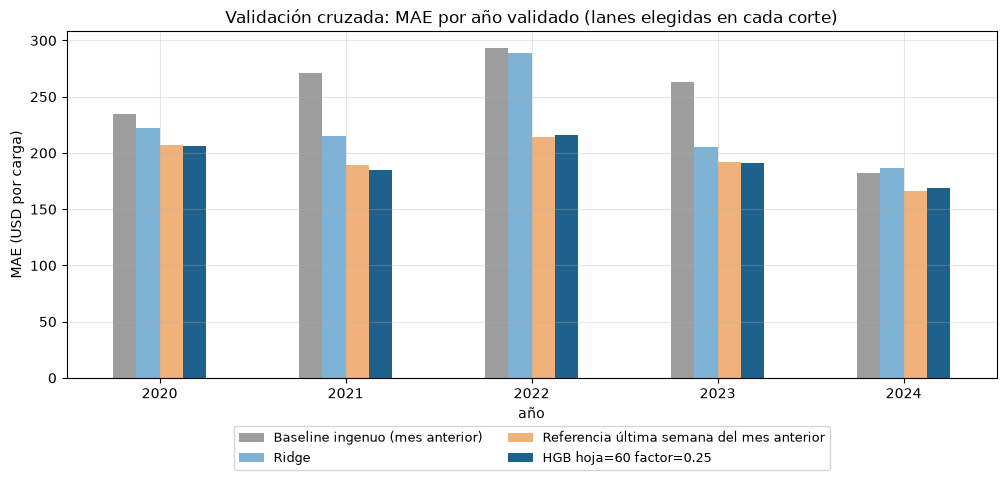

modelo,Baseline ingenuo (mes anterior),Ridge,Referencia última semana del mes anterior,HGB hoja=60 factor=0.25
año,,,,
2020,235.00,222.00,207.00,206.00
2021,271.00,215.00,190.00,185.00
2022,293.00,289.00,214.00,216.00
2023,263.00,205.00,192.00,191.00
2024,182.00,187.00,166.00,169.00


In [12]:
por_anio = resultados_cv.pivot(index="año", columns="modelo", values="MAE")
mostrar = ["Baseline ingenuo (mes anterior)", "Ridge", "Referencia última semana del mes anterior", mejor]
por_anio[mostrar].plot.bar(color=["#9e9e9e", "#7fb3d5", "#f0b27a", "#1f618d"], rot=0)
plt.title("Validación cruzada: MAE por año validado (lanes elegidas en cada corte)")
plt.ylabel("MAE (USD por carga)")
plt.legend(fontsize=9, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()
por_anio[mostrar].round(0)

**Interpretación.** El modelo seleccionado ("min_samples_leaf" = 60 y factor 0.25) tiene un MAE promedio de 193 USD por carga contra 249 del baseline del mes anterior, es decir, **22% menos error**, y un RMSE de 352 contra 418 (16% menos). Además le gana al baseline en los cinco años validados, incluido 2024, que fue el año más tranquilo (169 contra 182). La regresión Ridge (224) también mejora al baseline, pero queda claramente detrás de los árboles, y el baseline estacional (898) queda muy lejos, por lo que repetir el mismo mes del año previo no sirve como pronóstico mensual.

Sin embargo, la referencia de la última semana obtiene prácticamente lo mismo (194), por lo que la mayor parte de la mejora viene de usar la información más reciente y no de la complejidad del modelo. El modelo le gana a esa referencia por poco en 2020, 2021 y 2023 y pierde por poco en 2022 y 2024, y su principal aporte es reducir los errores grandes, ya que su RMSE es 1.5% menor (352 contra 357). Por último, aplicar el cambio completo (factor 1) empeora el MAE a 200, lo que indica que el modelo tiende a exagerar movimientos y que conviene usarlo como un ajuste moderado sobre la última semana.

## 8. Evaluación final en prueba

Entrenamos el modelo seleccionado una sola vez con todo el desarrollo de las 151 lanes elegibles en diciembre de 2024 y lo medimos en la prueba. Usamos el **MAE** como métrica principal porque se lee directo en USD por carga, el **RMSE** porque castiga los errores grandes, que son los que más afectan un presupuesto, el **WAPE** porque expresa el error como porcentaje del gasto total y permite comparar lanes cortas y largas, el **R²** y el **sesgo** (pronóstico menos real), que dice si el pronóstico se queda corto.

In [13]:
modelo_final = crear_modelo(hgb(MEJOR_HOJA)).fit(desarrollo[ENTRADAS], desarrollo[TARGET])
real = prueba["tarifa"].to_numpy()
pred_modelo = a_tarifa(prueba, modelo_final.predict(prueba[ENTRADAS]), MEJOR_FACTOR)
predicciones_prueba = {f"Modelo HGB (hoja={MEJOR_HOJA}, factor={MEJOR_FACTOR})": pred_modelo,
                       **{nombre: regla(prueba) for nombre, regla in BASELINES.items()}}

tabla_prueba = pd.DataFrame({nombre: metricas(real, pred) for nombre, pred in predicciones_prueba.items()}).T
tabla_prueba["Sesgo"] = [np.mean(pred - real) for pred in predicciones_prueba.values()]
tabla_prueba["Mejora del MAE vs mes anterior"] = 1 - tabla_prueba["MAE"] / tabla_prueba.loc["Baseline ingenuo (mes anterior)", "MAE"]
tabla_prueba.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "WAPE": "{:.1%}", "R2": "{:.3f}", "Sesgo": "{:,.0f}",
                           "Mejora del MAE vs mes anterior": "{:+.1%}"})

,MAE,RMSE,WAPE,R2,Sesgo,Mejora del MAE vs mes anterior
"Modelo HGB (hoja=60, factor=0.25)",242,428,4.5%,0.974,-16,+19.0%
Baseline ingenuo (mes anterior),299,504,5.6%,0.965,-73,+0.0%
Baseline estacional (mismo mes del año previo),632,"1,054",11.7%,0.845,-421,-111.1%
Referencia última semana del mes anterior,245,435,4.5%,0.973,-14,+18.2%


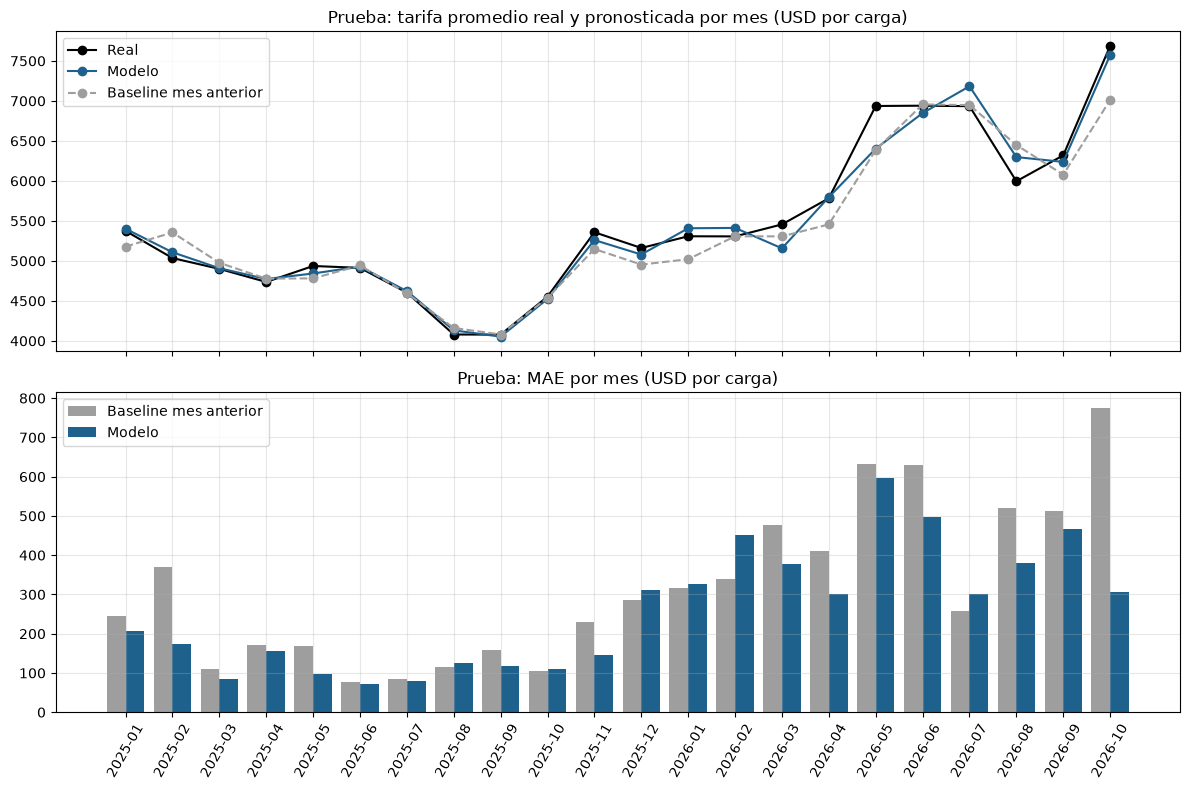

Meses en que el modelo tiene menor MAE que el baseline: 16 de 22


In [14]:
resultados = prueba[["lane", "mes", "tarifa_lag1", "ultima_semana_lag1", "tarifa", "cambio_lane"]].assign(
    pred_modelo=pred_modelo, pred_ingenuo=prueba["tarifa_lag1"].to_numpy())
resultados["error_modelo"] = (resultados["pred_modelo"] - resultados["tarifa"]).abs()
resultados["error_ingenuo"] = (resultados["pred_ingenuo"] - resultados["tarifa"]).abs()
por_mes = resultados.groupby("mes")[["tarifa", "pred_modelo", "pred_ingenuo", "error_modelo", "error_ingenuo"]].mean()

fig, ejes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
x, etiquetas = np.arange(len(por_mes)), por_mes.index.astype(str)
ejes[0].plot(x, por_mes["tarifa"], "o-", color="black", label="Real")
ejes[0].plot(x, por_mes["pred_modelo"], "o-", color="#1f618d", label="Modelo")
ejes[0].plot(x, por_mes["pred_ingenuo"], "o--", color="#9e9e9e", label="Baseline mes anterior")
ejes[0].set_title("Prueba: tarifa promedio real y pronosticada por mes (USD por carga)")
ejes[0].legend()
ejes[1].bar(x - 0.2, por_mes["error_ingenuo"], 0.4, color="#9e9e9e", label="Baseline mes anterior")
ejes[1].bar(x + 0.2, por_mes["error_modelo"], 0.4, color="#1f618d", label="Modelo")
ejes[1].set_title("Prueba: MAE por mes (USD por carga)")
ejes[1].legend()
plt.xticks(x, etiquetas, rotation=60)
plt.tight_layout()
plt.show()
print(f"Meses en que el modelo tiene menor MAE que el baseline: {(por_mes['error_modelo'] < por_mes['error_ingenuo']).sum()} de {len(por_mes)}")

**Interpretación.** En la prueba el modelo tiene un MAE de 242 USD por carga contra 299 del baseline del mes anterior, **19% menos error**, con un RMSE 15% menor (428 contra 504) y un WAPE de 4.5% del gasto contra 5.6%. La mejora es muy parecida a la de la validación cruzada (22%), lo cual indica que no depende del periodo. El sesgo también baja mucho, de -73 a -16 USD por carga, porque partir de la última semana hace que el pronóstico ya no se quede atrás en los periodos de alza. El R² en USD es alto para todos (0.97) porque casi toda la variación viene de que unas lanes son más caras que otras, así que no sirve para distinguir los pronósticos. Igual que en la validación cruzada, la referencia de la última semana queda muy cerca (245).

En las gráficas, el modelo sigue mucho mejor los cambios de nivel y tiene menor MAE en 16 de los 22 meses. Las mayores ventajas están en los meses de movimiento fuerte: octubre de 2026 (307 contra 776), cuando la subida ya se veía en la última semana de septiembre, y febrero de 2025 (173 contra 370). Pierde en algunos meses en que el cierre del mes anterior no se sostuvo, como febrero de 2026 (451 contra 339).

In [15]:
# ¿Dónde acierta y dónde falla? Según el cambio real del mes
resultados["tipo_mes"] = pd.cut(resultados["cambio_lane"], [-np.inf, -0.05, -0.0001, 0.0001, 0.05, np.inf],
                                labels=["baja > 5%", "baja 0 a 5%", "sin cambio", "sube 0 a 5%", "sube > 5%"])
por_tipo = resultados.groupby("tipo_mes", observed=True).agg(lane_meses=("tarifa", "size"),
                                                             mae_modelo=("error_modelo", "mean"), mae_ingenuo=("error_ingenuo", "mean"))
por_tipo["diferencia"] = por_tipo["mae_modelo"] - por_tipo["mae_ingenuo"]

# ¿Anticipa la dirección? En los lane-meses con movimiento de más de 3%
movimiento = resultados[resultados["cambio_lane"].abs() > 0.03]
acierto = (np.sign(np.log(movimiento["pred_modelo"] / movimiento["tarifa_lag1"])) == np.sign(movimiento["cambio_lane"])).mean()
print(f"Dirección correcta en {acierto:.0%} de los {len(movimiento):,} lane-meses con movimiento de más de 3% (el baseline no da dirección)")
por_tipo.style.format({"mae_modelo": "{:,.0f}", "mae_ingenuo": "{:,.0f}", "diferencia": "{:+,.0f}"})

Dirección correcta en 66% de los 613 lane-meses con movimiento de más de 3% (el baseline no da dirección)


,lane_meses,mae_modelo,mae_ingenuo,diferencia
tipo_mes,,,,
baja > 5%,204,391,543,-152
baja 0 a 5%,169,179,146,+34
sin cambio,346,8,0,+8
sube 0 a 5%,203,171,148,+23
sube > 5%,273,521,705,-183


**Interpretación.** El modelo reduce el error alrededor de 27% en los meses con cambios de más de 5%, tanto en alzas (521 contra 705) como en bajas (391 contra 543), que son los que más le cuestan al negocio. En cambio, cuando la tarifa no se mueve o se mueve poco, el baseline es mejor por entre 8 y 34 USD, ya que el modelo a veces traslada al mes siguiente un movimiento de la última semana que no se sostuvo. Además, en los lane-meses con movimientos de más de 3% el modelo acierta la dirección en 66% de los casos, algo que el baseline no puede hacer.

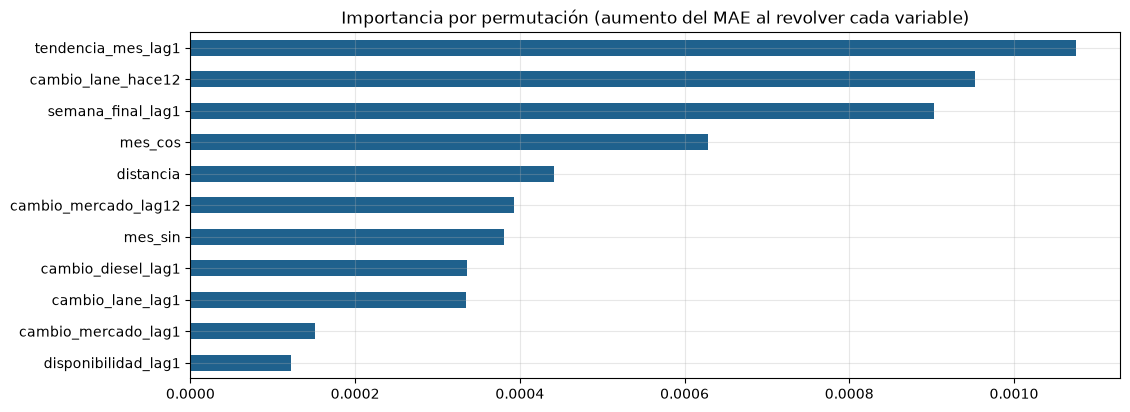

In [16]:
# Importancia por permutación: se calcula después de la evaluación, solo para interpretar
importancia = permutation_importance(modelo_final, prueba[ENTRADAS], prueba[TARGET], scoring="neg_mean_absolute_error",
                                     n_repeats=10, random_state=SEMILLA)
pd.Series(importancia.importances_mean, index=ENTRADAS).sort_values().plot.barh(color="#1f618d")
plt.title("Importancia por permutación (aumento del MAE al revolver cada variable)")
plt.show()

**Interpretación.** La importancia por permutación, calculada después de la evaluación y solo para interpretar, muestra que las variables más útiles son la tendencia dentro del mes anterior ("tendencia_mes_lag1"), la estacionalidad propia de la lane ("cambio_lane_hace12") y el cierre del mes anterior ("semana_final_lag1"), seguidas del calendario. La disponibilidad de camiones y el cambio de mercado del mes anterior son las que menos aportan, lo que coincide con las correlaciones de la sección 3.5.

## 9. Utilidad para el negocio

Para saber si la mejora es real calculamos un intervalo de confianza con **bootstrap por mes**: remuestreamos con reemplazo los 22 meses de la prueba, recalculamos la mejora y repetimos 2,000 veces. Remuestreamos meses completos porque las lanes de un mismo mes se mueven juntas y tratarlas como independientes daría un intervalo falsamente angosto. Después traducimos el error a dinero para un distribuidor que mueve 200 cargas spot al mes.

In [17]:
# Intervalo de confianza con bootstrap por MES (las lanes de un mismo mes se mueven juntas)
errores_mes = resultados.groupby("mes")[["error_modelo", "error_ingenuo"]].sum()
rng = np.random.default_rng(SEMILLA)
mejoras = [1 - m["error_modelo"].sum() / m["error_ingenuo"].sum()
           for m in (errores_mes.iloc[rng.integers(0, len(errores_mes), len(errores_mes))] for _ in range(2000))]
mejora = 1 - errores_mes["error_modelo"].sum() / errores_mes["error_ingenuo"].sum()
print(f"Mejora del MAE vs mes anterior: {mejora:.1%} (IC 95%: {np.percentile(mejoras, 2.5):.1%} a {np.percentile(mejoras, 97.5):.1%})")

# Traducción a dinero: un distribuidor con 200 cargas spot al mes en estas lanes
CARGAS = 200
mae_m, mae_b = resultados["error_modelo"].mean(), resultados["error_ingenuo"].mean()
print(f"Error absoluto del presupuesto mensual: modelo ${mae_m * CARGAS:,.0f} | baseline ${mae_b * CARGAS:,.0f} "
      f"| diferencia ${(mae_b - mae_m) * CARGAS:,.0f} al mes y ${(mae_b - mae_m) * CARGAS * 12:,.0f} al año")

Mejora del MAE vs mes anterior: 19.0% (IC 95%: 8.1% a 29.3%)
Error absoluto del presupuesto mensual: modelo $48,487 | baseline $59,871 | diferencia $11,383 al mes y $136,597 al año


**Interpretación.** El intervalo de 95% para la mejora del MAE va de 8.1% a 29.3%, así que aun en el escenario menos favorable el modelo es claramente mejor que repetir el mes anterior. Con 200 cargas al mes, el error absoluto del presupuesto bajaría de cerca de 59,900 a 48,500 USD, una diferencia de alrededor de 11,400 USD al mes o 137,000 al año. Este cálculo supone que los errores no se compensan entre lanes, por lo que es una cota superior que sirve para dimensionar y no un ahorro garantizado.

En cuanto a las consecuencias de los errores, quedarse corto en un mes de alza deja el presupuesto por debajo del gasto real, y el modelo reduce justo ese error (sesgo de -16 contra -73 USD). Sobreestimar en un mes tranquilo podría llevar a amarrar un contrato innecesario, que es donde el modelo pierde un poco. Por lo tanto, consideramos que el modelo es útil para el presupuesto mensual y como señal de dirección, aunque en la práctica la regla de la última semana ya captura casi todo el beneficio y sería una alternativa razonable si se quiere algo más sencillo de mantener.

## 10. Ejemplos y proyección

### 10.1 Predicciones en prueba (con valor real)
Elegimos los ejemplos sin escogerlos a mano: el registro en el percentil 10 del error (acierta), el 50 (típico) y el 90 (falla), entre las lanes activas en el último mes.

In [18]:
# Ejemplos sin escoger a mano: percentiles 10, 50 y 90 del error, entre lanes activas en el último mes
activas = resultados[resultados["lane"].isin(base.loc[base["mes"] == ULTIMO_MES, "lane"])].sort_values("error_modelo")
ejemplos = activas.iloc[[int(p * (len(activas) - 1)) for p in [0.1, 0.5, 0.9]]].assign(caso=["acierta (p10)", "típico (p50)", "falla (p90)"])
ejemplos[["caso", "lane", "mes", "tarifa_lag1", "ultima_semana_lag1", "pred_ingenuo", "pred_modelo", "tarifa"]].style.format(
    {c: "${:,.0f}" for c in ["tarifa_lag1", "ultima_semana_lag1", "pred_ingenuo", "pred_modelo", "tarifa"]}).hide(axis="index")

caso,lane,mes,tarifa_lag1,ultima_semana_lag1,pred_ingenuo,pred_modelo,tarifa
acierta (p10),"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → DALLAS",2025-05,"$5,150","$5,150","$5,150","$5,145","$5,150"
típico (p50),MEXICO CROSSINGS THROUGH SOUTH TEXAS → CHICAGO,2026-04,"$5,100","$5,300","$5,100","$5,296","$5,475"
falla (p90),SALINAS-WATSONVILLE CALIFORNIA → NEW YORK,2026-08,"$12,125","$11,900","$12,125","$11,892","$11,075"


**Interpretación.** En el caso donde acierta (Yakima Valley → Dallas, mayo de 2025) la tarifa no cambió y el modelo quedó a 5 USD. En el caso típico (Mexico Crossings Through South Texas → Chicago, abril de 2026) la última semana de marzo ya había subido a 5,300 contra una mediana de 5,100, el modelo pronosticó 5,296 y la tarifa real fue 5,475, por lo que se equivocó por 179 USD contra 375 del baseline. En el caso donde falla (Salinas-Watsonville → New York, agosto de 2026) la tarifa bajó casi 9% en un mes; el modelo partió de una última semana algo menor (11,900) y se equivocó por 817 USD contra 1,050 del baseline, lo que muestra que ninguno anticipa choques que todavía no aparecen en los datos.

### 10.2 Proyección para noviembre de 2026 (sin valor real)
Estas cifras **no** miden el desempeño, ya que la tarifa real de noviembre todavía no existe. Usamos el corte de octubre de 2026, que da exactamente las 94 lanes del E3, agregamos una fila futura para las que tienen dato en octubre, calculamos sus variables con la misma función y reentrenamos con toda su historia y la misma configuración, ya que en la práctica siempre se usaría la información más reciente.

In [19]:
# Proyección para noviembre de 2026 (sin valor real): corte de octubre de 2026 = las 94 lanes del E3
MES_FUTURO = ULTIMO_MES + 1
base_hoy = base[base["lane"].isin(lanes_hoy)]
futuro = base_hoy[base_hoy["mes"] == ULTIMO_MES][["origin", "destination", "lane", "distancia"]].assign(mes=MES_FUTURO)
panel_hoy = crear_variables(pd.concat([base_hoy, futuro], ignore_index=True))
historia = panel_hoy.dropna(subset=["tarifa", "tarifa_lag1"])
filas_futuras = panel_hoy[panel_hoy["mes"] == MES_FUTURO].reset_index(drop=True)

modelo_produccion = crear_modelo(hgb(MEJOR_HOJA)).fit(historia[ENTRADAS], historia[TARGET])   # toda la historia, misma configuración
filas_futuras["pronostico"] = a_tarifa(filas_futuras, modelo_produccion.predict(filas_futuras[ENTRADAS]), MEJOR_FACTOR)
filas_futuras["cambio_vs_octubre"] = filas_futuras["pronostico"] / filas_futuras["tarifa_lag1"] - 1
print(f"{len(filas_futuras)} lanes con dato en {ULTIMO_MES} | cambio promedio pronosticado para {MES_FUTURO}: "
      f"{filas_futuras['cambio_vs_octubre'].mean():+.1%}")

resultados.drop(columns="tipo_mes").assign(mes=resultados["mes"].astype(str)).to_csv("data/processed/predicciones_prueba.csv", index=False)
filas_futuras[["lane", "tarifa_lag1", "ultima_semana_lag1", "pronostico", "cambio_vs_octubre"]].assign(mes=str(MES_FUTURO)).to_csv(
    f"data/processed/proyeccion_{MES_FUTURO}.csv", index=False)
filas_futuras[filas_futuras["lane"].isin(ejemplos["lane"])][["lane", "tarifa_lag1", "ultima_semana_lag1", "pronostico", "cambio_vs_octubre"]].style.format(
    {"tarifa_lag1": "${:,.0f}", "ultima_semana_lag1": "${:,.0f}", "pronostico": "${:,.0f}", "cambio_vs_octubre": "{:+.1%}"}).hide(axis="index")

70 lanes con dato en 2026-10 | cambio promedio pronosticado para 2026-11: +0.1%


lane,tarifa_lag1,ultima_semana_lag1,pronostico,cambio_vs_octubre
MEXICO CROSSINGS THROUGH SOUTH TEXAS → CHICAGO,"$3,900","$3,900","$3,962",+1.6%
SALINAS-WATSONVILLE CALIFORNIA → NEW YORK,"$11,929","$12,482","$12,512",+4.9%
"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → DALLAS","$9,450","$9,000","$9,135",-3.3%


**Interpretación.** Para noviembre de 2026 el modelo proyecta un cambio promedio de +0.1% en las 70 lanes con dato en octubre, aunque con diferencias por lane de entre -9.9% y +7.5%, según cómo cerró cada una en la última semana de octubre. Por ejemplo, Salinas-Watsonville → New York cerró octubre por encima de su mediana y se proyecta +4.9%, mientras que Yakima Valley → Dallas cerró por debajo y se proyecta -3.3%. Las proyecciones de todas las lanes y las predicciones de prueba se guardan en "data/processed" para compararlas cuando USDA publique los datos reales.

## 11. Conclusiones

**Qué logramos.** Construimos un prototipo de pronóstico mensual por lane que reduce el error 19% contra el baseline del mes anterior en la prueba (MAE de 242 contra 299 USD por carga, intervalo de 95% de 8.1% a 29.3%) y 22% en la validación cruzada, ganando en los cinco años validados, y que supera por mucho al baseline del mismo mes del año previo (632). Lo hicimos con una metodología que respeta el tiempo en cada paso: las lanes se eligen en cada corte con la información disponible, la última semana usada siempre es anterior al mes pronosticado, el pipeline se ajusta solo con entrenamiento y la prueba se usa una sola vez.

**De dónde viene la mejora.** El hallazgo más importante es que la información más reciente, la última semana del mes que acaba de cerrar, anticipa buena parte del mes siguiente. Una regla que solo usa esa semana obtiene casi la misma mejora (245 en prueba), por lo que el Gradient Boosting aporta poco encima de ella, principalmente en los errores grandes. También aprendimos que la versión anterior de este entregable, sin la última semana y con las lanes elegidas con información de 2026, mostraba una mejora de 5.5% que venía en buena parte del sesgo de supervivencia y que bajó a 1.5% al corregirlo.

**Qué no quedó resuelto.** El modelo no anticipa choques que todavía no aparecen en los datos, es peor que el baseline cuando la tarifa casi no se mueve, porque a veces traslada un movimiento pasajero de la última semana, y trabaja con tarifas de mercado de USDA y no con lo que paga la empresa. Además, los resultados aplican a lanes con al menos 36 meses de historia y actividad reciente.

**Qué mejoraríamos.** Probaríamos pronosticar a nivel semanal y agregar después al mes, agregaríamos variables que anticipen choques (volúmenes de embarque de USDA o índices de capacidad), daríamos intervalos de predicción con regresión por cuantiles en lugar de un solo número y, con datos internos de la empresa, mediríamos el ahorro real de decidir entre spot y contrato.

## 12. Referencias bibliográficas

- U.S. Department of Agriculture, Agricultural Marketing Service. (2026). *Refrigerated Truck Rates and Availability* [Conjunto de datos; copia con datos al 27 de octubre de 2026]. AgTransport. https://agtransport.usda.gov/d/acar-e3r8
- U.S. Energy Information Administration. (2026). *Weekly U.S. No 2 Diesel Retail Prices* [Conjunto de datos]. https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=EMD_EPD2D_PTE_NUS_DPG&f=W
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3a ed.). OTexts. https://otexts.com/fpp3/